In [69]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid, save_image
import matplotlib.pyplot as plt
import numpy as np
import gc
import os
from PIL import Image
import torch.optim as optim
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import matplotlib.pyplot as plt
from torchvision.utils import make_grid
from torchvision.io import read_image
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gc.collect()
torch.cuda.empty_cache()

In [70]:
!pip install pillow-heif
!pip install torch_optimizer
!pip install -U albumentations
!pip install torch_fidelity

In [71]:
import pillow_heif

# Register HEIC
pillow_heif.register_heif_opener()

PATCH_SIZE = 128
def keep_first_channel(img, **kwargs):
    return img[..., :1]

albumentations_transform = A.Compose([
    A.Resize(height=256, width=300),
    A.CenterCrop(height=PATCH_SIZE, width=PATCH_SIZE),
    A.ToGray(p=1.0),
    A.Lambda(image=keep_first_channel, p=1.0),  # Keep only the first channel
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.96, 1.04), translate_percent=0.01, rotate=0, p=0.25),
    A.HorizontalFlip(p=0.5),
    # A.VerticalFlip(p=0.5),
    # A.RandomRotate90(p=0.5),
    # A.Transpose(p=0.5),
    A.Affine(scale=(0.96,1.04), translate_percent=0.01, rotate=0, p=0.25),

    A.RandomBrightnessContrast(p=0.5),
    A.RandomGamma(p=0.25),
    A.Emboss(p=0.25),
    A.Blur(blur_limit=3, p=0.01),
    A.OneOf([
        A.ElasticTransform(alpha=120, sigma=6, p=1.0),
        A.GridDistortion(p=1.0),
        A.OpticalDistortion(distort_limit=2.0, p=1.0),
    ], p=0.8),
    A.Normalize(mean=(0.5,), std=(0.5,)),
    ToTensorV2(),
])



In [72]:
class CustomImageDataset(Dataset):
    def __init__(self, image_dir):
        self.image_dir = image_dir
        self.image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.heic'))]

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        path = os.path.join(self.image_dir, self.image_files[idx])
        img = Image.open(path).convert('RGB')
        img_np = np.array(img)  # return raw NumPy, no transform here
        return img_np, self.image_files[idx]


In [73]:
class CustomImageDatasetLoader(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        self.image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.heic'))]

    def __len__(self):
        return len(self.image_files)
    def __getitem__(self, idx):
        path = os.path.join(self.image_dir, self.image_files[idx])
        img  = Image.open(path).convert('RGB')

        if self.transform:
            img_np    = np.array(img)                     # PIL→H×W×C NumPy
            augmented = self.transform(image=img_np)      # <-- pass as keyword
            img_tensor = augmented['image']               # torch.Tensor from ToTensorV2
            return img_tensor, 0

        # if no transform, fallback to pure PIL→Tensor
        return transforms.ToTensor()(img), 0
    

In [74]:
gray_tansform = A.Compose([
    A.Resize(height=256, width=300),
    A.CenterCrop(height=PATCH_SIZE, width=PATCH_SIZE),
    A.ToGray(p=1.0),
    A.Lambda(image=keep_first_channel),
    A.Normalize(mean=(0.5,), std=(0.5,)),
    ToTensorV2(),
])

In [75]:
data_path = "/kaggle/input/dataset/processed_images"

In [76]:
dataset = CustomImageDatasetLoader(image_dir=data_path, transform=gray_tansform)
train_loader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=0)

In [77]:

class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super(Generator, self).__init__()
        self.noise_dim = noise_dim
        
        self.fc = nn.Sequential(
            nn.Linear(noise_dim, 256 * 8 * 8),
            nn.BatchNorm1d(256 * 8 * 8),
            nn.ReLU(True)
        )
        
        self.up_blocks = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 16x16
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 32x32
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 64x64
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(True),  
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),  # 128x128
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.fc(x)
        x = x.view(-1, 256, 8, 8)
        x = self.up_blocks(x)
        return x


In [78]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),   # 64x64
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),  # 32x32
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # 16x16
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # 8x8
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), # 4x4
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)


In [79]:
# Using available hardware device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Creating the generator and discriminator
latent_dim = 100
generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)

# creating binary cross entropy loss instancea
criterion = nn.BCELoss()

In [80]:
checkpoint_dir = "/kaggle/input/models/checkpoints"
generator_checkpoint_path = os.path.join(checkpoint_dir, "generator.pth")
discriminator_checkpoint_path = os.path.join(checkpoint_dir, "discriminator.pth")

In [81]:
generator.eval()

Generator(
  (fc): Sequential(
    (0): Linear(in_features=100, out_features=16384, bias=True)
    (1): BatchNorm1d(16384, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (up_blocks): Sequential(
    (0): Upsample(scale_factor=2.0, mode='bilinear')
    (1): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU(inplace=True)
    (4): Upsample(scale_factor=2.0, mode='bilinear')
    (5): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): Upsample(scale_factor=2.0, mode='bilinear')
    (9): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): Ups

In [88]:

# Load the generator and discriminator
generator = Generator(100).to(device)
discriminator = Discriminator().to(device)

# Load state dicts
generator.load_state_dict(torch.load(generator_checkpoint_path))
discriminator.load_state_dict(torch.load(discriminator_checkpoint_path))

<All keys matched successfully>

In [ ]:
def generate_random_image(generator, latent_dim=100):
    generator.eval() 
    noise = torch.randn(1, latent_dim).to(device)
    with torch.no_grad():
        generated_image = generator(noise)
    return generated_image


# Function to calculate similarity between two images
def calculate_similarity(image1, image2):
    image1_flat = image1.view(-1)
    image2_flat = image2.view(-1)
    similarity = torch.nn.functional.cosine_similarity(image1_flat, image2_flat, dim=0)
    return similarity.item()

original_image, _ = next(iter(train_loader))
original_image = original_image[0].to(device)  #
generated_image = generate_random_image(generator)  
similarity = calculate_similarity(original_image, generated_image.squeeze())
print(f"Similarity between original and generated image: {similarity:.4f}")

Similarity between original and generated image: 0.0791


In [ ]:
from skimage.metrics import structural_similarity as ssim
import torch.nn.functional as F
from torch_fidelity import calculate_metrics
import os

def calculate_ssim(img1, img2):
    img1_np = img1.squeeze().cpu().numpy()
    img2_np = img2.squeeze().cpu().numpy()
    return ssim(img1_np, img2_np, data_range=1.0)

def calculate_psnr(img1, img2, max_pixel=1.0):
    mse = F.mse_loss(img1, img2)
    if mse == 0:
        return float('inf')
    return 20 * torch.log10(max_pixel / torch.sqrt(mse))

def calculate_fid_is(real_dir, fake_dir):
    metrics = calculate_metrics(
        input1=real_dir,
        input2=fake_dir,
        fid=True,
        isc=True,
        cuda=True
    )
    fid = metrics.get('fid50k_full') or metrics['frechet_inception_distance']
    is_score = metrics.get('isc_mean') or metrics['inception_score_mean']
    return fid, is_score



Batch shape: torch.Size([64, 1, 128, 128])


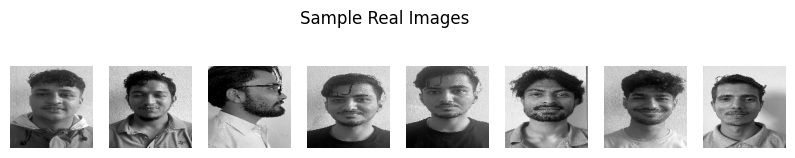

In [91]:
import matplotlib.pyplot as plt

real_sample, _ = next(iter(train_loader))
print("Batch shape:", real_sample.shape)  # Should be [B, 1, 128, 128]

# Plot the first few images
plt.figure(figsize=(10, 2))
for i in range(8):
    plt.subplot(1, 8, i+1)
    plt.imshow(real_sample[i][0].cpu().numpy(), cmap='gray')  # shape [1,H,W]
    plt.axis('off')
plt.suptitle("Sample Real Images")
plt.show()


In [ ]:
real_sample, _ = next(iter(train_loader))
real_sample = real_sample[:16]
generator.eval()
fake_sample = generator(torch.randn(16, latent_dim).to(device)).detach()

# Scale to [0,1]
real_sample = (real_sample + 1) / 2
fake_sample = (fake_sample + 1) / 2

os.makedirs("real_imgs", exist_ok=True)
os.makedirs("fake_imgs", exist_ok=True)

for i in range(16):
    save_image(real_sample[i], f"real_imgs/real_{i}.png")
    save_image(fake_sample[i], f"fake_imgs/fake_{i}.png")


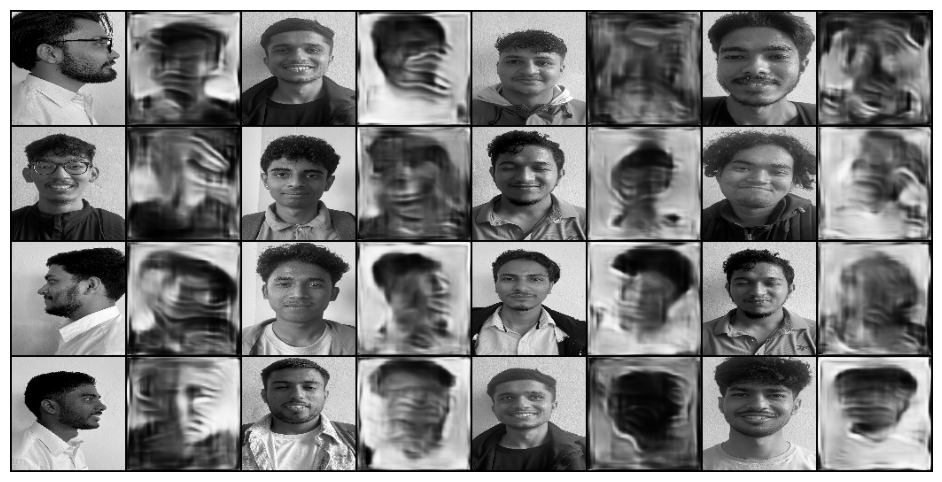

In [ ]:
real_images = []
fake_images = []

for i in range(16):
    real_path = f"real_imgs/real_{i}.png"
    fake_path = f"fake_imgs/fake_{i}.png"
    
    real_img = read_image(real_path).float() / 255.0  # shape [C,H,W]
    fake_img = read_image(fake_path).float() / 255.0

    real_images.append(real_img)
    fake_images.append(fake_img)

interleaved = []
for r, f in zip(real_images, fake_images):
    interleaved.extend([r, f])

grid = make_grid(interleaved, nrow=8, padding=2)

# Plot
plt.figure(figsize=(12, 6))
plt.imshow(grid.permute(1, 2, 0).cpu().numpy())
plt.axis("off")
# plt.title("Real (Left) vs Fake (Right) — Side by Side (Calculating FID and IS)")
plt.savefig("fid_score.pdf", format="pdf")
plt.show()


In [ ]:
img1 = real_sample[0].to(device)
img2 = fake_sample[0].to(device)
ssim_val = calculate_ssim(img1, img2)
psnr_val = calculate_psnr(img1, img2)

fid_val, is_val = calculate_fid_is("real_imgs", "fake_imgs")

print(f"SSIM: {ssim_val:.4f}")
print(f"PSNR: {psnr_val:.2f} dB")
print(f"FID: {fid_val:.2f}")
print(f"Inception Score: {is_val:.2f}")


Creating feature extractor "inception-v3-compat" with features ['2048', 'logits_unbiased']
Extracting features from input1
Looking for samples non-recursivelty in "real_imgs" with extensions png,jpg,jpeg
Found 16 samples
Processing samples                                                      
Extracting features from input2
Looking for samples non-recursivelty in "fake_imgs" with extensions png,jpg,jpeg
Found 16 samples
Processing samples                                                      
Inception Score: 1.1262064070839515 ± 0.13010732204265324


SSIM: 0.0865
PSNR: 7.62 dB
FID: 403.05
Inception Score: 1.13


Frechet Inception Distance: 403.0539608397082
